# Credit Card Fraud Detection

In [ ]:
import warnings

In [ ]:
warnings.simplefilter("ignore", category=DeprecationWarning)


In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import folium
from transformers import BertTokenizer, TFBertModel

In [ ]:
#reading data
card_info = pd.read_csv('/content/synthetic_credit_card_data.csv')
transaction_info = pd.read_csv('/content/newTransactions.csv')

In [ ]:
card_info.head()

,credit_card,city,state,zipcode,credit_card_limit
0,3176589639979744,Chicago,IL,83000,9457
1,4052838530802285,Phoenix,AZ,78562,3852
2,3057851067063787,New York,NY,48253,15212
3,9449210960244473,Los Angeles,CA,78596,7247
4,6689983183420875,San Antonio,TX,82304,12048


In [ ]:
transaction_info.head()

,credit_card,date,transaction_dollar_amount,Longitude,Latitude
0,3176589639979744,2022-08-29 08:19:42.963872796,7736.95,-114.344755,4.508105
1,3176589639979744,2022-08-23 05:06:09.178073961,3633.83,-37.241350,-14.795946
2,3176589639979744,2022-03-05 09:40:57.608273455,9163.75,98.250463,-83.268683
3,3176589639979744,2022-10-15 07:08:03.571157947,2483.10,-87.945304,6.934093
4,3176589639979744,2022-06-13 03:40:15.021708483,6093.97,-77.339761,-2.948214


In [ ]:
#check for missing values
card_info.isnull().sum()

credit_card          0
city                 0
state                0
zipcode              0
credit_card_limit    0
dtype: int64

In [ ]:
#check for missing values
transaction_info.isnull().sum()

credit_card                  0
date                         0
transaction_dollar_amount    0
Longitude                    0
Latitude                     0
dtype: int64

In [ ]:
#merge two dataframes
df = transaction_info.merge(card_info, on = 'credit_card')

In [ ]:
df.head()

,credit_card,date,transaction_dollar_amount,Longitude,Latitude,city,state,zipcode,credit_card_limit
0,3176589639979744,2022-08-29 08:19:42.963872796,7736.95,-114.344755,4.508105,Chicago,IL,83000,9457
1,3176589639979744,2022-08-23 05:06:09.178073961,3633.83,-37.241350,-14.795946,Chicago,IL,83000,9457
2,3176589639979744,2022-03-05 09:40:57.608273455,9163.75,98.250463,-83.268683,Chicago,IL,83000,9457
3,3176589639979744,2022-10-15 07:08:03.571157947,2483.10,-87.945304,6.934093,Chicago,IL,83000,9457
4,3176589639979744,2022-06-13 03:40:15.021708483,6093.97,-77.339761,-2.948214,Chicago,IL,83000,9457


In [ ]:
#shape of data
df.shape

(8000, 9)

## Data Visaulization

<Axes: >

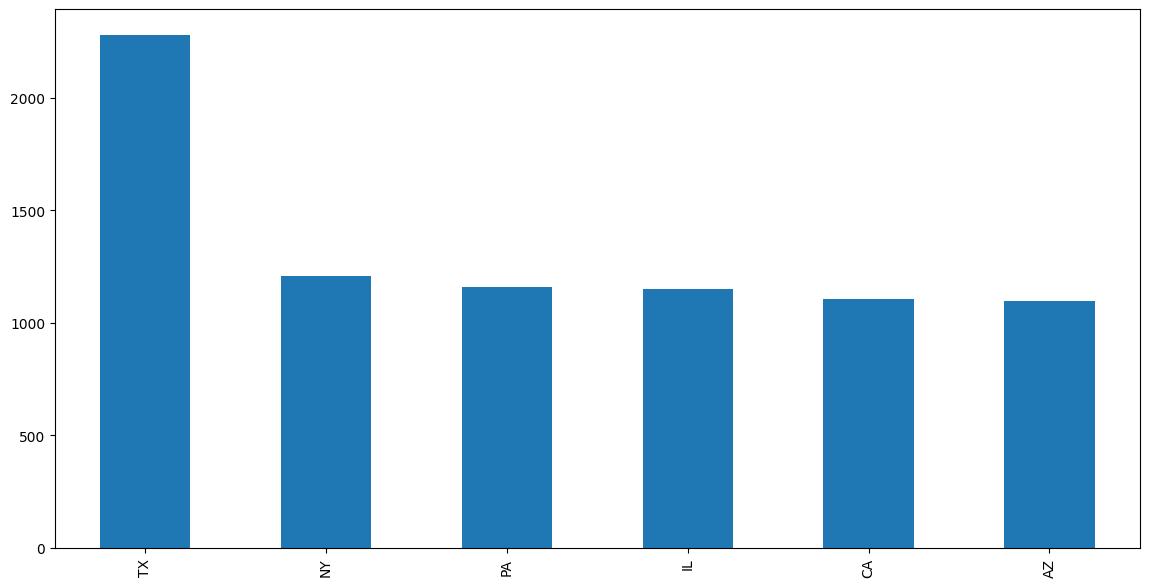

In [ ]:
# Number of Transaction records state wise
df['state'].value_counts().plot(kind='bar', figsize = (14,7))

In [ ]:
def visualize_total_transactions_on_map(df):
    city_total_transactions = df.groupby('city')['transaction_dollar_amount'].sum().reset_index()

    map_center_lat = df['Latitude'].mean()
    map_center_lon = df['Longitude'].mean()
    map_osm = folium.Map(location=[map_center_lat, map_center_lon], zoom_start=10)

    max_total_transactions = city_total_transactions['transaction_dollar_amount'].max()

    for index, row in city_total_transactions.iterrows():
        city = row['city']
        total_transactions = row['transaction_dollar_amount']

        marker_size = total_transactions / max_total_transactions * 50  # Adjust the scaling factor as needed

        popup_text = f"City: {city}<br>Total Transactions: ${total_transactions:.2f}"

        marker = folium.CircleMarker(
            location=[df[df['city'] == city]['Latitude'].mean(), df[df['city'] == city]['Longitude'].mean()],
            radius=marker_size,
            popup=popup_text,
            tooltip=city,
            fill=True,
            fill_opacity=0.7
        )

        marker.add_to(map_osm)

    return map_osm

if __name__ == "__main__":

    map_total_transactions = visualize_total_transactions_on_map(df)
    display(map_total_transactions)

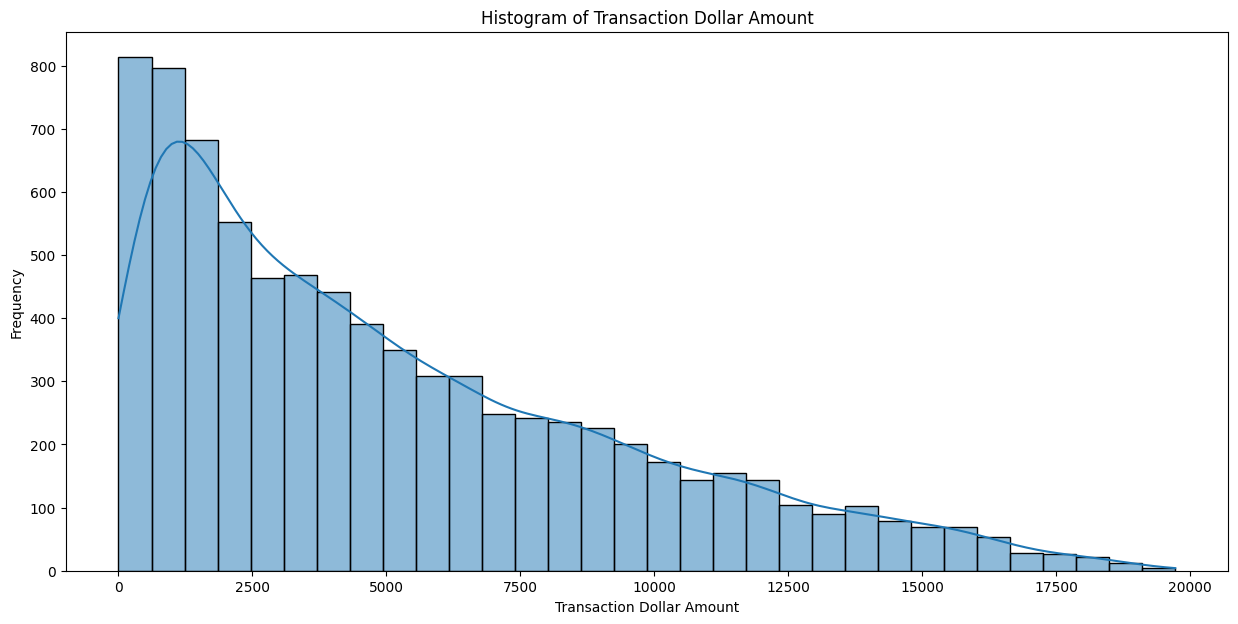

In [ ]:
# Histogram of 'transaction_dollar_amount'

plt.figure(figsize=(15, 7))
sns.histplot(df['transaction_dollar_amount'], kde=True)
plt.title('Histogram of Transaction Dollar Amount')
plt.xlabel('Transaction Dollar Amount')
plt.ylabel('Frequency')
plt.show()

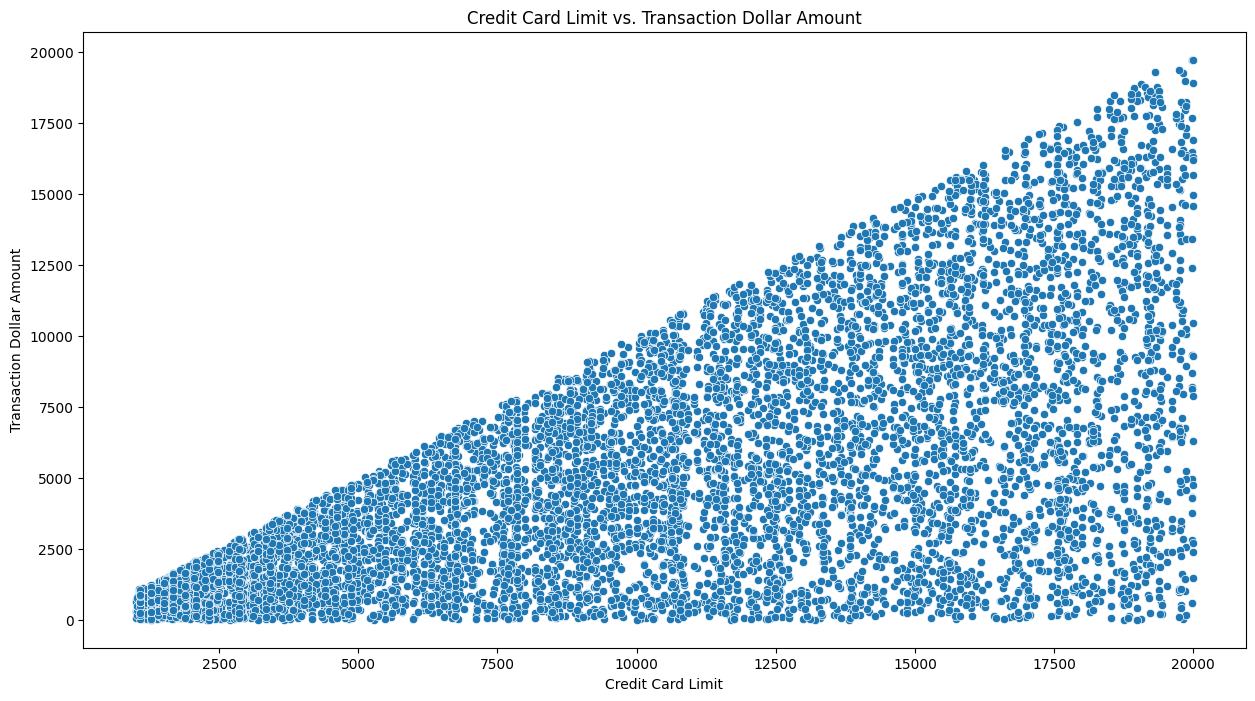

In [ ]:
#'transaction_dollar_amount' vs. 'credit_card_limit'
plt.figure(figsize=(15, 8))
sns.scatterplot(data=df, x='credit_card_limit', y='transaction_dollar_amount')
plt.title('Credit Card Limit vs. Transaction Dollar Amount')
plt.xlabel('Credit Card Limit')
plt.ylabel('Transaction Dollar Amount')
plt.show()


<ipython-input-18-34519d458f11>:3: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')


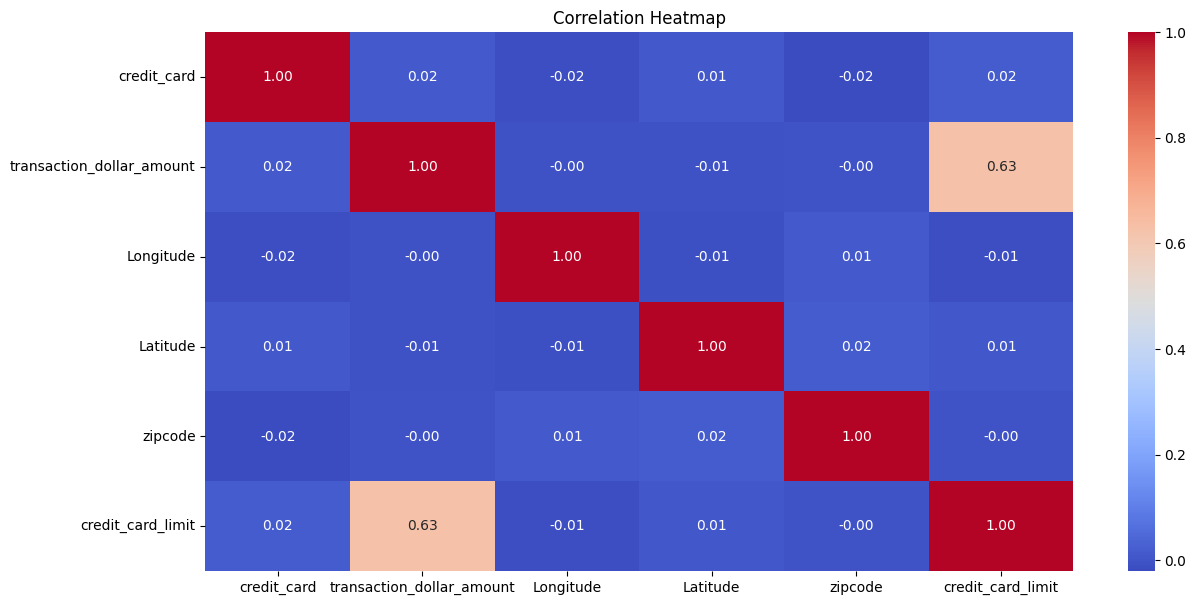

In [ ]:
#Heatmap of correlation between numerical features
plt.figure(figsize=(14, 7))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()


## Building Fraud Detection Model

In [ ]:
pip install transformers

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 21.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.8/268.8 kB 27.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 61.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 57.4 MB/s eta 0:00:00


In [ ]:
pip install neupy


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.8/226.8 kB 4.1 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of neupy to determine which version is compatible with other requirements. This could take a while.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.0/226.0 kB 7.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.7/224.7 kB 8.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.3/212.3 kB 8.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 208.5/208.5 kB 9.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 208.0/208.0 kB 9.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 198.6/198.6 kB 10.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 197.2/197.2 kB 10.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 22.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Created wheel for tableprint: filename=tablepri

In [ ]:
pip install imbalanced-learn

Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFBertModel: ['cls.predictions.transform.LayerNorm.weight', 'cls.seq_relationship.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.predictions.bias', 'cls.predictions.transform.LayerNorm.bias', 'cls.seq_relationship.bias']
- This IS expected if you are initializing TFBertModel from a PyTorch model trained on another task or with another architecture (e.g. initializing a TFBertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFBertModel from a PyTorch model that you expect to be exactly identical (e.g. initializing a TFBertForSequenceClassification model from a BertForSequenceClassification model).
All the weights of TFBertModel were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFBertModel for predictions w

Model Training Complete.
50/50 [==============================] - 0s 1ms/step
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       912
           1       0.99      0.97      0.98       688

    accuracy                           0.98      1600
   macro avg       0.99      0.98      0.98      1600
weighted avg       0.98      0.98      0.98      1600

Confusion Matrix:
[[907   5]
 [ 20 668]]


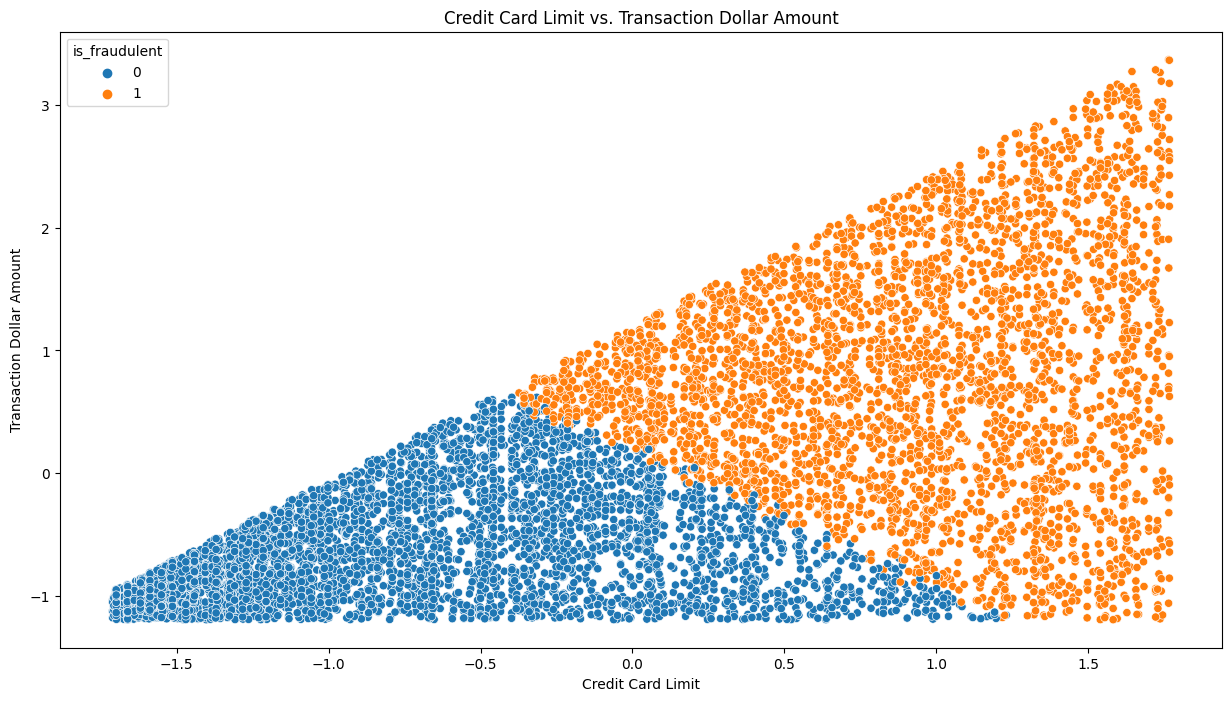

In [ ]:
class FraudDetectionModel:
    def __init__(self, df):
        self.df = df
        self.feature_columns = ['transaction_dollar_amount', 'Longitude', 'Latitude', 'credit_card_limit']
        self.model = None
        self.kmeans = None
        self.bert_tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
        self.bert_model = TFBertModel.from_pretrained('bert-base-uncased')

    def data_preprocessing(self):
        scaler = StandardScaler()
        self.df[self.feature_columns] = scaler.fit_transform(self.df[self.feature_columns])

    def build_kmeans(self, n_clusters=2):
        self.kmeans = KMeans(n_clusters=n_clusters, random_state=42)

    def create_labels(self):
        if self.kmeans is None:
            raise ValueError("K-means model has not been built yet. Please call 'build_kmeans' first.")

        self.kmeans.fit(self.df[self.feature_columns])
        self.df['cluster_label'] = self.kmeans.predict(self.df[self.feature_columns])
        self.df['is_fraudulent'] = self.df['cluster_label']

    def build_model(self, input_shape):
        self.model = tf.keras.Sequential([
            tf.keras.layers.Dense(64, activation='relu', input_shape=input_shape),
            tf.keras.layers.Dense(32, activation='relu'),
            tf.keras.layers.Dense(1, activation='sigmoid')
        ])
        self.model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    def train_model(self, X_train, y_train, epochs=10, batch_size=32):
        self.model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, verbose=0)

    def evaluate_model(self, X_test, y_test, threshold=0.5):
        loss, accuracy = self.model.evaluate(X_test, y_test)

        y_pred = (self.model.predict(X_test) > threshold).astype(int).flatten()
        print("Classification Report:")
        print(classification_report(y_test, y_pred))
        print("Confusion Matrix:")
        print(confusion_matrix(y_test, y_pred))

    def build_bert_embeddings(self):
        text = self.df['city'].tolist()
        tokenized_text = self.bert_tokenizer(text, padding=True, truncation=True, return_tensors='tf')
        bert_outputs = self.bert_model(**tokenized_text)
        self.df['bert_embeddings'] = bert_outputs.last_hidden_state.numpy().tolist()

if __name__ == "__main__":
    # Load your DataFrame 'df' here

    model = FraudDetectionModel(df)
    model.data_preprocessing()
    model.build_kmeans()
    model.create_labels()

    model.build_bert_embeddings()  # Keep BERT integration

    # Combine BERT embeddings with the other features
    bert_embeddings = np.array(model.df['bert_embeddings'].tolist())
    bert_embeddings = bert_embeddings.mean(axis=1)  # Averaging the embeddings across the sequence length
    X_other_features = model.df[model.feature_columns].values
    X = np.concatenate([X_other_features, bert_embeddings], axis=1)


    y = model.df['is_fraudulent'].values

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model.build_model(input_shape=(X.shape[1],))
    model.train_model(X_train, y_train, epochs=10, batch_size=32)

    print("Model Training Complete.")

    model.evaluate_model(X_test, y_test, threshold=0.5)

    plt.figure(figsize=(15, 8))
    sns.scatterplot(data=model.df, x='credit_card_limit', y='transaction_dollar_amount', hue='is_fraudulent')
    plt.title('Credit Card Limit vs. Transaction Dollar Amount')
    plt.xlabel('Credit Card Limit')
    plt.ylabel('Transaction Dollar Amount')
    plt.show()


In [ ]:
pip install imbalanced-learn

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)


Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFBertModel: ['cls.predictions.transform.LayerNorm.weight', 'cls.seq_relationship.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.predictions.bias', 'cls.predictions.transform.LayerNorm.bias', 'cls.seq_relationship.bias']
- This IS expected if you are initializing TFBertModel from a PyTorch model trained on another task or with another architecture (e.g. initializing a TFBertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFBertModel from a PyTorch model that you expect to be exactly identical (e.g. initializing a TFBertForSequenceClassification model from a BertForSequenceClassification model).
All the weights of TFBertModel were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFBertModel for predictions w

DBN Training Complete.
50/50 [==============================] - 0s 2ms/step
DBN Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       912
           1       0.97      0.99      0.98       688

    accuracy                           0.99      1600
   macro avg       0.98      0.99      0.99      1600
weighted avg       0.99      0.99      0.99      1600

DBN Confusion Matrix:
[[894  18]
 [  4 684]]


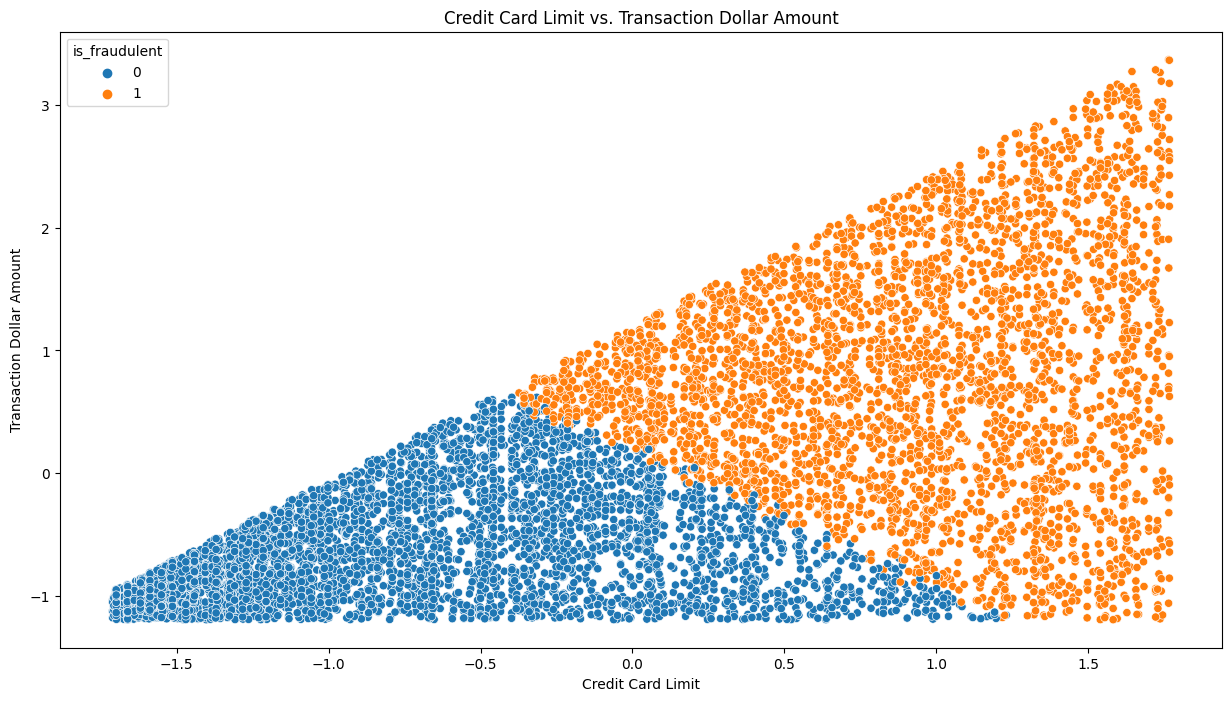

In [ ]:
class FraudDetectionModel:
    def __init__(self, df):
          self.df = df
          self.feature_columns = ['transaction_dollar_amount', 'Longitude', 'Latitude', 'credit_card_limit']
          self.model = None
          self.kmeans = None
          self.bert_tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
          self.bert_model = TFBertModel.from_pretrained('bert-base-uncased')
          self.dbn_model = None

    def build_dbn_model(self, num_hidden_layers=2):
          self.dbn_model = DBN(hidden_layers_structure=[100] * num_hidden_layers,
                              learning_rate_rbm=0.06,
                              n_epochs_rbm=10,
                              verbose=True)

    def train_dbn_model(self):
        X = self.df[self.feature_columns].values
        self.dbn_model.fit(X)


    def build_nn_model(self):
          self.dbn_model = tf.keras.Sequential([
              tf.keras.layers.Dense(100, activation='sigmoid', input_shape=(len(self.feature_columns),)),
              tf.keras.layers.Dense(50, activation='sigmoid'),
              tf.keras.layers.Dense(1, activation='sigmoid')
          ])
          self.dbn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    def train_nn_model(self, X_train, y_train, epochs=10, batch_size=32):
          self.dbn_model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, verbose=0)

    def data_preprocessing(self):
          scaler = StandardScaler()
          self.df[self.feature_columns] = scaler.fit_transform(self.df[self.feature_columns])

    def build_kmeans(self, n_clusters=2):
          self.kmeans = KMeans(n_clusters=n_clusters, random_state=42)

    def create_labels(self):
          if self.kmeans is None:
              raise ValueError("K-means model has not been built yet. Please call 'build_kmeans' first.")

          self.kmeans.fit(self.df[self.feature_columns])

          # Introduce some label noise by randomly assigning a portion of the cluster to non-fraudulent
          self.df['cluster_label'] = self.kmeans.predict(self.df[self.feature_columns])


    def visualize_fraudulent_transactions(self):
          plt.figure(figsize=(15, 8))
          sns.scatterplot(data=self.df, x='credit_card_limit', y='transaction_dollar_amount', hue='is_fraudulent')
          plt.title('Credit Card Limit vs. Transaction Dollar Amount')
          plt.xlabel('Credit Card Limit')
          plt.ylabel('Transaction Dollar Amount')
          plt.show()

    def build_model(self):
          self.model = tf.keras.Sequential([
              tf.keras.layers.Dense(64, activation='relu', input_shape=(len(self.feature_columns),)),
              tf.keras.layers.Dense(32, activation='relu'),
              tf.keras.layers.Dense(1, activation='sigmoid')
          ])
          self.model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    def train_model(self, X_train, y_train, epochs=10, batch_size=32):
          self.model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, verbose=0)

    def evaluate_model(self, X_test, y_test, threshold=0.5):
          loss, accuracy = self.model.evaluate(X_test, y_test)

          y_pred = (self.model.predict(X_test) > threshold).astype(int).flatten()
          print("Classification Report:")
          print(classification_report(y_test, y_pred))
          print("Confusion Matrix:")
          print(confusion_matrix(y_test, y_pred))

    def build_bert_embeddings(self):
          text = self.df['city'].tolist()
          tokenized_text = self.bert_tokenizer(text, padding=True, truncation=True, return_tensors='tf')
          bert_outputs = self.bert_model(**tokenized_text)
          self.df['bert_embeddings'] = bert_outputs.last_hidden_state.numpy().tolist()
    def get_feature_matrix(self):
          X_numeric = self.df[self.feature_columns].values
          X_bert = np.array(self.df['bert_embeddings'].tolist())
          X_bert = X_bert.mean(axis=1)  # Averaging embeddings over sequence length
          return np.hstack((X_numeric, X_bert))



    def build_dbn(self):
          input_shape = self.get_feature_matrix().shape[1]
          self.dbn_model = tf.keras.Sequential([
            tf.keras.layers.Dense(128, activation='relu', input_shape=(input_shape,)),
            tf.keras.layers.Dense(64, activation='relu'),
            tf.keras.layers.Dense(1, activation='sigmoid')
           ])
          self.dbn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])



    def train_dbn(self, X_train, y_train, epochs=10, batch_size=32):
        self.dbn_model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, verbose=0)

    def evaluate_dbn(self, X_test, y_test, threshold=0.5):
        loss, accuracy = self.dbn_model.evaluate(X_test, y_test)

        y_pred = (self.dbn_model.predict(X_test) > threshold).astype(int).flatten()
        print("DBN Classification Report:")
        print(classification_report(y_test, y_pred))
        print("DBN Confusion Matrix:")
        print(confusion_matrix(y_test, y_pred))

if __name__ == "__main__":
    # Load your DataFrame 'df' here

    model = FraudDetectionModel(df)
    model.data_preprocessing()
    model.build_kmeans()
    model.create_labels()
    model.build_bert_embeddings()  # Keep BERT integration

    X = model.get_feature_matrix()
    y = model.df['is_fraudulent'].values

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Handle class imbalance using SMOTE
    smote = SMOTE(random_state=42)
    X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

    model.build_dbn()
    model.train_dbn(X_resampled, y_resampled, epochs=10, batch_size=32)

    print("DBN Training Complete.")

    model.evaluate_dbn(X_test, y_test, threshold=0.5)  # Adjust threshold based on ROC later if necessary

    plt.figure(figsize=(15, 8))
    sns.scatterplot(data=model.df, x='credit_card_limit', y='transaction_dollar_amount', hue='is_fraudulent')
    plt.title('Credit Card Limit vs. Transaction Dollar Amount')
    plt.xlabel('Credit Card Limit')
    plt.ylabel('Transaction Dollar Amount')
    plt.show()


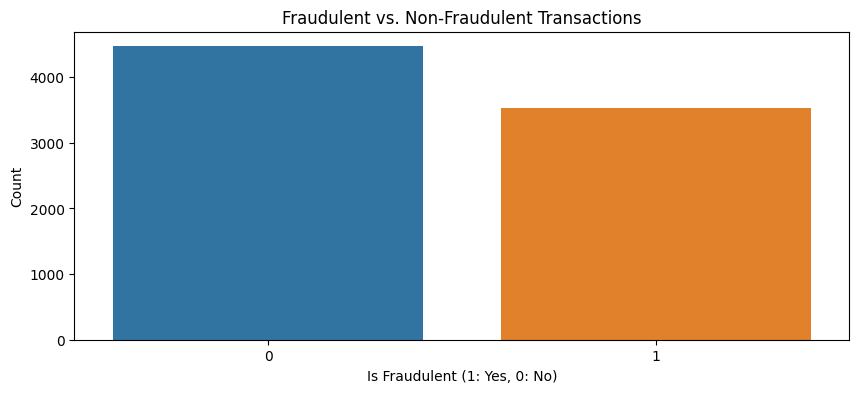

In [ ]:
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x='is_fraudulent')
plt.title('Fraudulent vs. Non-Fraudulent Transactions')
plt.xlabel('Is Fraudulent (1: Yes, 0: No)')
plt.ylabel('Count')
plt.show()


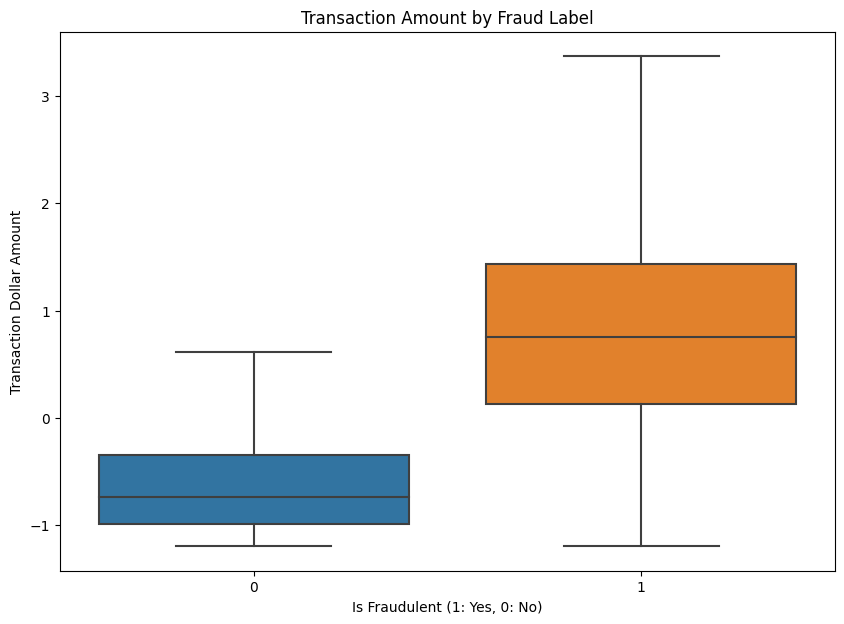

In [ ]:
plt.figure(figsize=(10, 7))
sns.boxplot(data=df, x='is_fraudulent', y='transaction_dollar_amount')
plt.title('Transaction Amount by Fraud Label')
plt.xlabel('Is Fraudulent (1: Yes, 0: No)')
plt.ylabel('Transaction Dollar Amount')
plt.show()

<ipython-input-30-92d836a39865>:3: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matrix = df.corr()


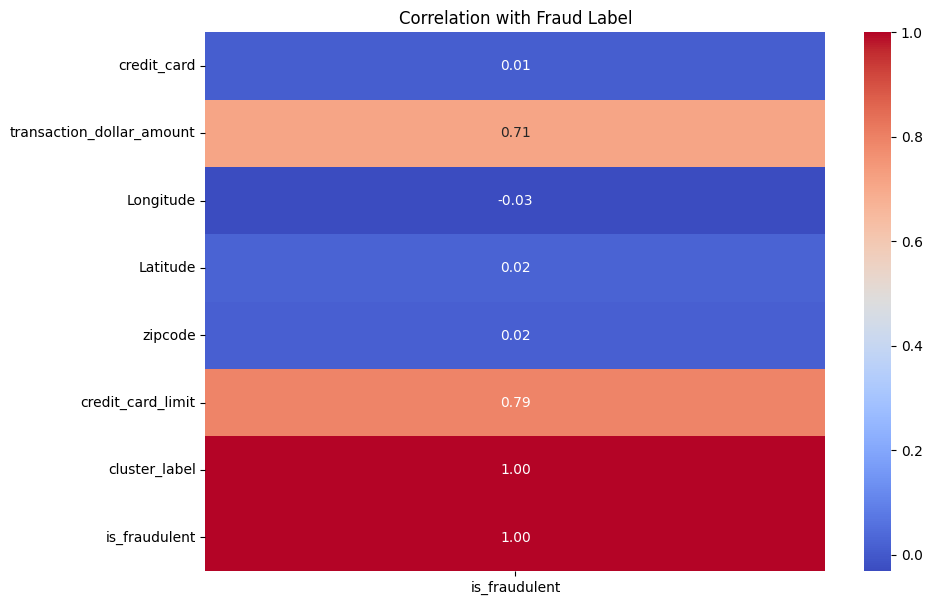

In [ ]:
#correlation of fraud transaction with other features
plt.figure(figsize=(10, 7))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix[['is_fraudulent']], annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation with Fraud Label')
plt.show()


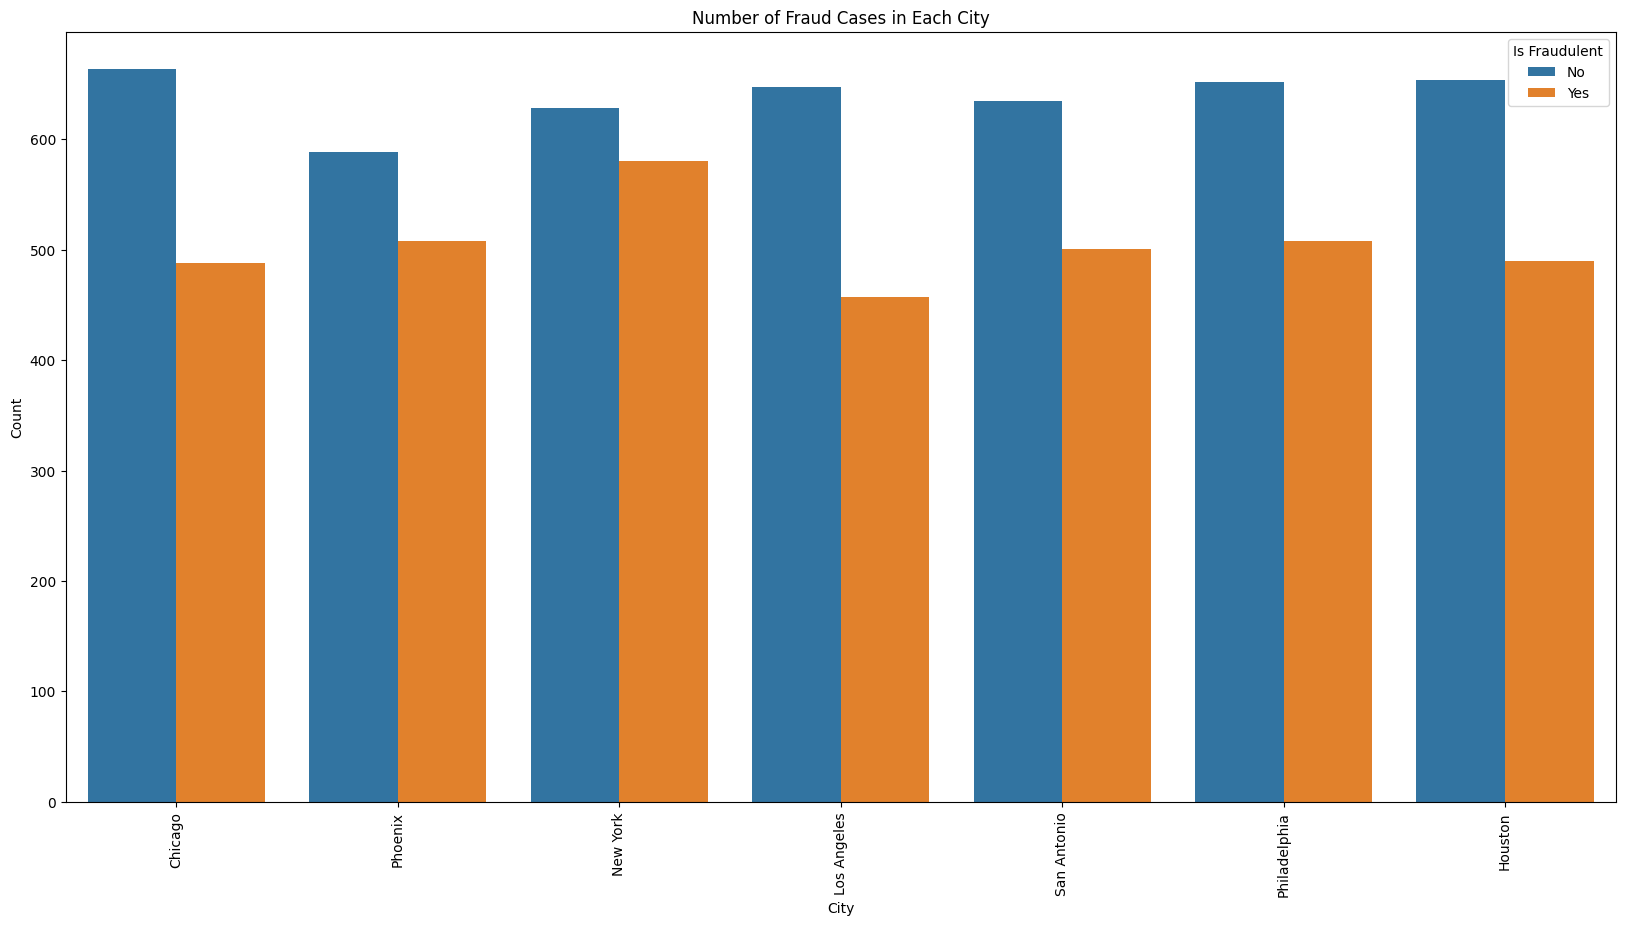

In [ ]:
plt.figure(figsize=(20, 10))
sns.countplot(data=df, x='city', hue='is_fraudulent')
plt.title('Number of Fraud Cases in Each City')
plt.xlabel('City')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.legend(title='Is Fraudulent', labels=['No', 'Yes'])
plt.show()


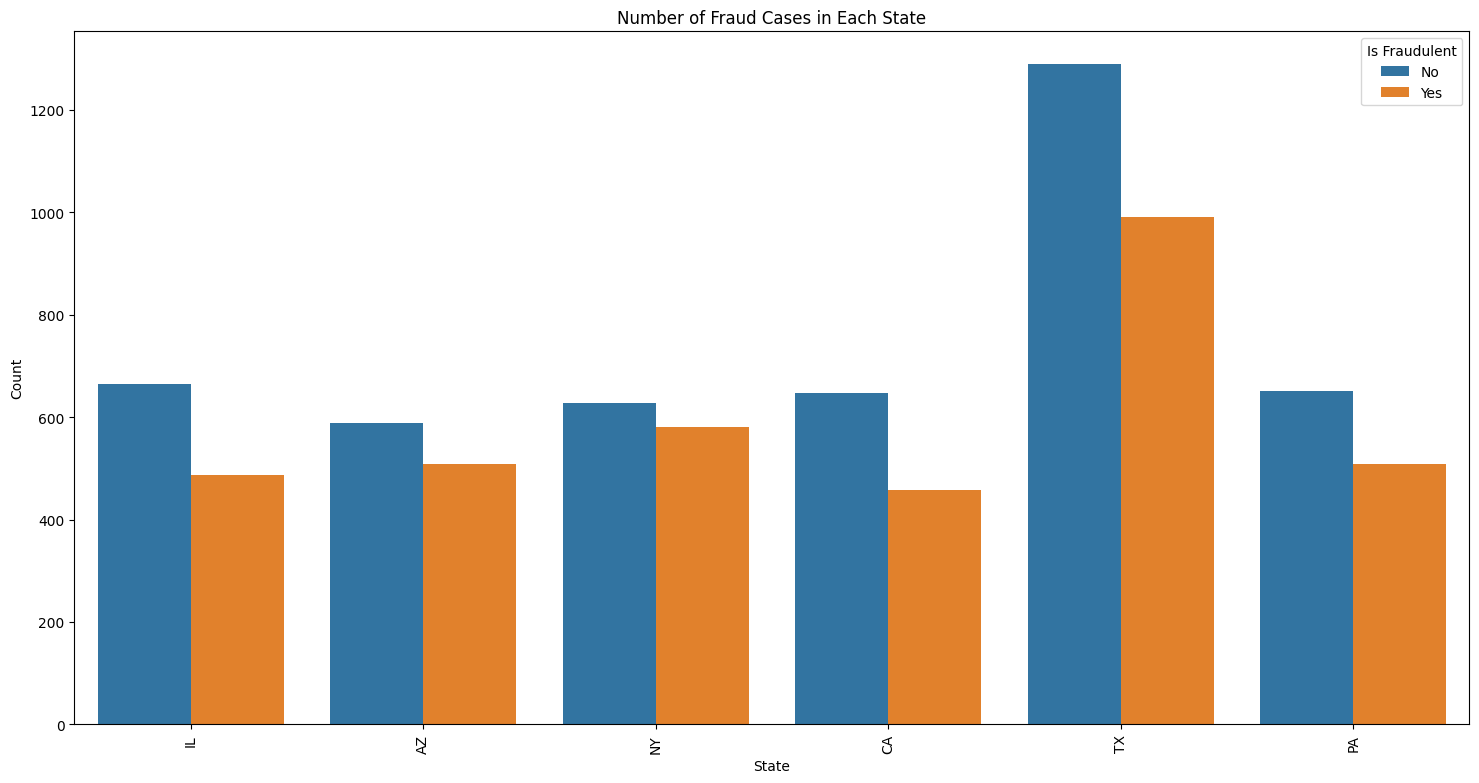

In [ ]:
plt.figure(figsize=(18, 9))
sns.countplot(data=df, x='state', hue='is_fraudulent')
plt.title('Number of Fraud Cases in Each State')
plt.xlabel('State')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.legend(title='Is Fraudulent', labels=['No', 'Yes'])
plt.show()